In [8]:
from sklearn.datasets import load_breast_cancer, load_wine

cancer = load_breast_cancer()
wine = load_wine()

In [9]:
import pandas as pd

# Breast Cancer dataset
df_cancer = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)
df_cancer["target"] = cancer.target

# Wine dataset
df_wine = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)
df_wine["target"] = wine.target

print("Breast Cancer Dataset:")
display(df_cancer.head())

print("Wine Dataset:")
display(df_wine.head())

Breast Cancer Dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Wine Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Dataset 1: Breast Cancer
X1 = cancer.data
y1 = cancer.target

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)

model1 = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000))
])

model1.fit(X1_train, y1_train)
pred1 = model1.predict(X1_test)

print("Breast Cancer Accuracy:",
      accuracy_score(y1_test, pred1))


# Dataset 2: Wine
X2 = wine.data
y2 = wine.target

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

model2 = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000))
])

model2.fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

print("Wine Dataset Accuracy:",
      accuracy_score(y2_test, pred2))

Breast Cancer Accuracy: 0.9824561403508771
Wine Dataset Accuracy: 0.9722222222222222


BREAST CANCER CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



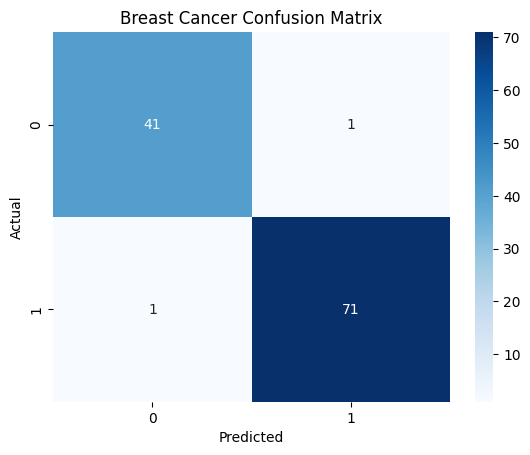

WINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



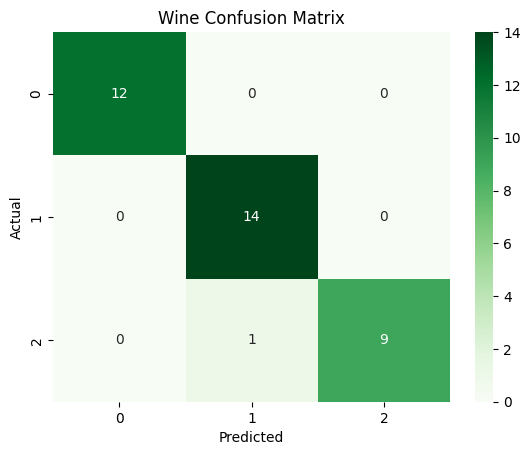

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Breast Cancer evaluation
print("BREAST CANCER CLASSIFICATION REPORT")
print(classification_report(y1_test, pred1,
                            target_names=cancer.target_names))

cm1 = confusion_matrix(y1_test, pred1)

sns.heatmap(cm1, annot=True, fmt="d", cmap="Blues")
plt.title("Breast Cancer Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Wine evaluation
print("WINE CLASSIFICATION REPORT")
print(classification_report(y2_test, pred2,
                            target_names=wine.target_names))

cm2 = confusion_matrix(y2_test, pred2)

sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens")
plt.title("Wine Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [12]:
!pip -q install gradio
import gradio as gr
import numpy as np

# Breast Cancer prediction
def predict_cancer(*values):
    data = np.array(values).reshape(1, -1)
    prediction = model1.predict(data)[0]
    probabilities = model1.predict_proba(data)[0]

    label = cancer.target_names[prediction]

    return {
        cancer.target_names[i]: float(probabilities[i])
        for i in range(len(cancer.target_names))
    }, f"Predicted class: {label}"


# Wine prediction
def predict_wine(*values):
    data = np.array(values).reshape(1, -1)
    prediction = model2.predict(data)[0]
    probabilities = model2.predict_proba(data)[0]

    label = wine.target_names[prediction]

    return {
        wine.target_names[i]: float(probabilities[i])
        for i in range(len(wine.target_names))
    }, f"Predicted class: {label}"


with gr.Blocks(title="Logistic Regression Project") as demo:

    gr.Markdown("# Logistic Regression Classification")
    gr.Markdown("Two datasets: Breast Cancer and Wine Recognition")

    with gr.Tab("Breast Cancer"):
        cancer_inputs = []

        for name, value in zip(
            cancer.feature_names,
            cancer.data.mean(axis=0)
        ):
            cancer_inputs.append(
                gr.Number(label=name, value=float(value))
            )

        cancer_output = gr.Label(label="Class Probabilities")
        cancer_text = gr.Textbox(label="Prediction")

        gr.Button("Predict Cancer Class").click(
            predict_cancer,
            inputs=cancer_inputs,
            outputs=[cancer_output, cancer_text]
        )

    with gr.Tab("Wine Recognition"):
        wine_inputs = []

        for name, value in zip(
            wine.feature_names,
            wine.data.mean(axis=0)
        ):
            wine_inputs.append(
                gr.Number(label=name, value=float(value))
            )

        wine_output = gr.Label(label="Class Probabilities")
        wine_text = gr.Textbox(label="Prediction")

        gr.Button("Predict Wine Class").click(
            predict_wine,
            inputs=wine_inputs,
            outputs=[wine_output, wine_text]
        )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ab49a5278000b724a5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
!pip -q install flask pyngrok
!pip -q install pyngrok

from pyngrok import ngrok

ngrok.set_auth_token("YOUR_NGROK_AUTH_TOKEN")

In [15]:
from flask import Flask, request, render_template_string
import numpy as np
from pyngrok import ngrok

app = Flask(__name__)

HTML = """
<h1>Logistic Regression Classification</h1>

<form method="POST">
    <label>Select Dataset:</label>
    <select name="dataset" onchange="this.form.submit()">
        <option value="cancer" {% if selected == 'cancer' %}selected{% endif %}>
            Breast Cancer
        </option>
        <option value="wine" {% if selected == 'wine' %}selected{% endif %}>
            Wine Recognition
        </option>
    </select>

    {% for feature, value in features %}
        <p>
            {{ feature }}:
            <input type="number" step="any"
                   name="{{ loop.index0 }}" value="{{ value }}" required>
        </p>
    {% endfor %}

    <button type="submit">Predict</button>
</form>

<h2>{{ result }}</h2>
"""

@app.route("/", methods=["GET", "POST"])
def home():
    selected = request.values.get("dataset", "cancer")

    if selected == "wine":
        data = wine
        model = model2
    else:
        selected = "cancer"
        data = cancer
        model = model1

    defaults = data.data.mean(axis=0).tolist()
    values = defaults
    result = ""

    if request.method == "POST":
        try:
            values = [
                float(request.form.get(str(i), defaults[i]))
                for i in range(len(data.feature_names))
            ]

            prediction = model.predict(
                np.array(values).reshape(1, -1)
            )[0]

            result = "Predicted class: " + data.target_names[prediction]

        except (ValueError, TypeError):
            result = "Please enter valid numerical values."

    features = list(zip(data.feature_names, values))

    return render_template_string(
        HTML,
        selected=selected,
        features=features,
        result=result
    )

# Create a temporary public URL
public_url = ngrok.connect(5000)
print("Open your Flask website here:", public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-14T08:42:51+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_NGROK_AUTH_TOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-14T08:42:51+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_NGROK_AUTH_TOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_NGROK_AUTH_TOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.